<a href="https://colab.research.google.com/github/AnnsuChoudhary/Fake-News-Misinformation-Detection-Platform/blob/main/propagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision torchaudio
!pip install torch_geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.2 MB/s eta 0:00:00


In [ ]:
from google.colab import files
uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
import zipfile

with zipfile.ZipFile("all-rnr-annotated-threads.zip", 'r') as zip_ref:
    zip_ref.extractall()

In [ ]:
import os

os.rename("all-rnr-annotated-threads", "pheme")

In [ ]:
print(os.listdir("pheme"))

['._ferguson-all-rnr-threads', 'ebola-essien-all-rnr-threads', '._putinmissing-all-rnr-threads', '._ottawashooting-all-rnr-threads', '._ebola-essien-all-rnr-threads', '._sydneysiege-all-rnr-threads', 'prince-toronto-all-rnr-threads', '._.DS_Store', '._prince-toronto-all-rnr-threads', 'ottawashooting-all-rnr-threads', 'gurlitt-all-rnr-threads', 'sydneysiege-all-rnr-threads', 'charliehebdo-all-rnr-threads', '._germanwings-crash-all-rnr-threads', '.DS_Store', 'putinmissing-all-rnr-threads', '._gurlitt-all-rnr-threads', 'ferguson-all-rnr-threads', '._charliehebdo-all-rnr-threads', 'germanwings-crash-all-rnr-threads']


In [ ]:
import os
import shutil

base_path = "pheme"

for item in os.listdir(base_path):
    if item.startswith("._") or item == ".DS_Store":
        path = os.path.join(base_path, item)
        if os.path.isdir(path):
            shutil.rmtree(path)
        else:
            os.remove(path)

print(os.listdir(base_path))

['ebola-essien-all-rnr-threads', 'prince-toronto-all-rnr-threads', 'ottawashooting-all-rnr-threads', 'gurlitt-all-rnr-threads', 'sydneysiege-all-rnr-threads', 'charliehebdo-all-rnr-threads', 'putinmissing-all-rnr-threads', 'ferguson-all-rnr-threads', 'germanwings-crash-all-rnr-threads']


In [ ]:
import os
import json
import torch
from torch_geometric.data import Data
from datetime import datetime

graphs = []

base_path = "pheme"

def parse_time(t):
    return datetime.strptime(t, "%a %b %d %H:%M:%S %z %Y")

for event in os.listdir(base_path):
    if event.startswith("._") or event == ".DS_Store":
        continue

    event_path = os.path.join(base_path, event)

    if not os.path.isdir(event_path):
        continue

    for category in ["rumours", "non-rumours"]:
        category_path = os.path.join(event_path, category)

        if not os.path.exists(category_path):
            continue

        label = 0 if category == "rumours" else 1

        for thread in os.listdir(category_path):
            if thread.startswith("._"):
                continue

            thread_path = os.path.join(category_path, thread)

            source_path = os.path.join(thread_path, "source-tweets")
            reactions_path = os.path.join(thread_path, "reactions")

            try:
                source_file = os.listdir(source_path)[0]
                with open(os.path.join(source_path, source_file)) as f:
                    source = json.load(f)
            except:
                continue

            try:
                source_time = parse_time(source["created_at"])
            except:
                continue

            nodes = []
            edges = []

            # ✅ ROOT NODE (2 features now)
            nodes.append([0.0, 0.0])

            node_id = 1

            if os.path.exists(reactions_path):
                for reply_file in os.listdir(reactions_path):
                    if reply_file.startswith("._"):
                        continue

                    try:
                        with open(os.path.join(reactions_path, reply_file)) as f:
                            reply = json.load(f)

                        reply_time = parse_time(reply["created_at"])
                        time_diff = (reply_time - source_time).total_seconds()

                        # ✅ NOW 2 FEATURES
                        nodes.append([
                            time_diff / 10000,   # normalized time
                            node_id / 100        # structural signal
                        ])

                        edges.append([0, node_id])
                        edges.append([node_id, 0])

                        node_id += 1

                    except:
                        continue

            if len(nodes) < 2:
                continue

            x = torch.tensor(nodes, dtype=torch.float)
            edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
            y = torch.tensor([label], dtype=torch.long)

            graphs.append(Data(x=x, edge_index=edge_index, y=y))

print("✅ Total graphs created:", len(graphs))

✅ Total graphs created: 2894


In [ ]:
from sklearn.model_selection import train_test_split

train_graphs, test_graphs = train_test_split(
    graphs, test_size=0.2, random_state=42, stratify=[g.y.item() for g in graphs]
)

print("Train:", len(train_graphs), "Test:", len(test_graphs))

Train: 2315 Test: 579


In [ ]:
from torch_geometric.loader import DataLoader

train_loader = DataLoader(train_graphs, batch_size=64, shuffle=True)
test_loader = DataLoader(test_graphs, batch_size=64)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool

class GCN(nn.Module):
    def __init__(self):
        super(GCN, self).__init__()

        # ✅ INPUT = 2 features now
        self.conv1 = GCNConv(2, 32)
        self.conv2 = GCNConv(32, 64)
        self.conv3 = GCNConv(64, 64)

        self.lin = nn.Linear(64, 2)

    def forward(self, x, edge_index, batch):
        x = self.conv1(x, edge_index)
        x = F.relu(x)

        x = self.conv2(x, edge_index)
        x = F.relu(x)

        x = self.conv3(x, edge_index)
        x = F.relu(x)

        x = global_mean_pool(x, batch)
        x = self.lin(x)

        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = GCN().to(device)

# ✅ Slightly safer learning rate
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)

criterion = nn.CrossEntropyLoss()

In [ ]:
def train():
    model.train()
    total_loss = 0

    for data in train_loader:
        data = data.to(device)

        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)

        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss


def test(loader):
    model.eval()
    correct = 0

    for data in loader:
        data = data.to(device)

        out = model(data.x, data.edge_index, data.batch)
        pred = out.argmax(dim=1)

        correct += int((pred == data.y).sum())

    return correct / len(loader.dataset)


for epoch in range(1, 51):  # 🔥 20 epochs for better accuracy
    loss = train()
    acc = test(test_loader)

    print(f"Epoch {epoch}, Loss: {loss:.4f}, Accuracy: {acc:.4f}")

Epoch 1, Loss: 23.7407, Accuracy: 0.6390
Epoch 2, Loss: 23.3089, Accuracy: 0.6390
Epoch 3, Loss: 23.3374, Accuracy: 0.6390
Epoch 4, Loss: 23.2217, Accuracy: 0.6390
Epoch 5, Loss: 23.2477, Accuracy: 0.6459
Epoch 6, Loss: 23.1353, Accuracy: 0.6442
Epoch 7, Loss: 22.9743, Accuracy: 0.6494
Epoch 8, Loss: 23.0611, Accuracy: 0.6477
Epoch 9, Loss: 23.0424, Accuracy: 0.6477
Epoch 10, Loss: 22.8764, Accuracy: 0.6546
Epoch 11, Loss: 22.5972, Accuracy: 0.6390
Epoch 12, Loss: 23.0738, Accuracy: 0.6442
Epoch 13, Loss: 22.8993, Accuracy: 0.6408
Epoch 14, Loss: 22.8200, Accuracy: 0.6459
Epoch 15, Loss: 22.7366, Accuracy: 0.6459
Epoch 16, Loss: 22.8280, Accuracy: 0.6459
Epoch 17, Loss: 22.7580, Accuracy: 0.6459
Epoch 18, Loss: 22.7881, Accuracy: 0.6442
Epoch 19, Loss: 22.8078, Accuracy: 0.6563
Epoch 20, Loss: 22.9896, Accuracy: 0.6511
Epoch 21, Loss: 22.9971, Accuracy: 0.6511
Epoch 22, Loss: 22.9138, Accuracy: 0.6459
Epoch 23, Loss: 22.7924, Accuracy: 0.6442
Epoch 24, Loss: 22.7713, Accuracy: 0.6425
E

In [ ]:
import torch

torch.save(model.state_dict(), "gnn_propagation_model.pth")

print("✅ Model saved successfully!")

✅ Model saved successfully!


In [ ]:
from google.colab import files
files.download("gnn_propagation_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool

class GCN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = GCNConv(2, 64)
        self.conv2 = GCNConv(64, 128)
        self.conv3 = GCNConv(128, 128)

        self.dropout = nn.Dropout(0.3)

        self.lin = nn.Linear(128, 2)

    def forward(self, x, edge_index, batch):

        x = F.relu(self.conv1(x, edge_index))
        x = self.dropout(x)

        x = F.relu(self.conv2(x, edge_index))
        x = self.dropout(x)

        x = F.relu(self.conv3(x, edge_index))

        x = global_mean_pool(x, batch)

        x = self.lin(x)

        return x

In [ ]:
model = GCN().to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

criterion = nn.CrossEntropyLoss()

In [ ]:
def train():
    model.train()
    total_loss = 0

    for data in train_loader:
        data = data.to(device)

        optimizer.zero_grad()
        out = model(data.x, data.edge_index, data.batch)

        loss = criterion(out, data.y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss


def test(loader):
    model.eval()
    correct = 0

    for data in loader:
        data = data.to(device)

        out = model(data.x, data.edge_index, data.batch)
        pred = out.argmax(dim=1)

        correct += int((pred == data.y).sum())

    return correct / len(loader.dataset)


for epoch in range(1, 51):  # 🔥 20 epochs for better accuracy
    loss = train()
    acc = test(test_loader)

    print(f"Epoch {epoch}, Loss: {loss:.4f}, Accuracy: {acc:.4f}")

Epoch 1, Loss: 23.7504, Accuracy: 0.6390
Epoch 2, Loss: 23.5525, Accuracy: 0.6390
Epoch 3, Loss: 23.4252, Accuracy: 0.6390
Epoch 4, Loss: 23.4862, Accuracy: 0.6390
Epoch 5, Loss: 23.9691, Accuracy: 0.6390
Epoch 6, Loss: 23.2290, Accuracy: 0.6390
Epoch 7, Loss: 23.0083, Accuracy: 0.6442
Epoch 8, Loss: 22.9252, Accuracy: 0.6408
Epoch 9, Loss: 22.7639, Accuracy: 0.6390
Epoch 10, Loss: 22.9405, Accuracy: 0.6356
Epoch 11, Loss: 22.8161, Accuracy: 0.6425
Epoch 12, Loss: 22.8462, Accuracy: 0.6425
Epoch 13, Loss: 22.8715, Accuracy: 0.6580
Epoch 14, Loss: 22.8484, Accuracy: 0.6390
Epoch 15, Loss: 22.8373, Accuracy: 0.6442
Epoch 16, Loss: 23.0528, Accuracy: 0.6442
Epoch 17, Loss: 22.8143, Accuracy: 0.6408
Epoch 18, Loss: 23.0116, Accuracy: 0.6373
Epoch 19, Loss: 22.7997, Accuracy: 0.6459
Epoch 20, Loss: 22.8058, Accuracy: 0.6511
Epoch 21, Loss: 22.6539, Accuracy: 0.6459
Epoch 22, Loss: 22.9133, Accuracy: 0.6459
Epoch 23, Loss: 22.8782, Accuracy: 0.6580
Epoch 24, Loss: 22.6633, Accuracy: 0.6494
E

In [ ]:
import torch

model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.no_grad():

    for data in test_loader:

        data = data.to(device)

        outputs = model(
            data.x,
            data.edge_index,
            data.batch
        )

        probs = torch.softmax(
            outputs,
            dim=1
        )[:,1]

        preds = outputs.argmax(dim=1)

        y_true.extend(
            data.y.cpu().numpy()
        )

        y_pred.extend(
            preds.cpu().numpy()
        )

        y_prob.extend(
            probs.cpu().numpy()
        )

print("Samples:", len(y_true))

Samples: 579


In [ ]:
from sklearn.metrics import *

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(y_true, y_pred)

recall = recall_score(y_true, y_pred)

f1 = f1_score(y_true, y_pred)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred
)

mcc = matthews_corrcoef(
    y_true,
    y_pred
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nBalanced Accuracy:", balanced_acc)

print("MCC:", mcc)

print("ROC-AUC:", roc_auc)

Accuracy : 0.6511226252158895
Precision: 0.675
Recall   : 0.8756756756756757
F1 Score : 0.7623529411764706

Balanced Accuracy: 0.5646320962110436
MCC: 0.16489748291167367
ROC-AUC: 0.64788568472779


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print(
    classification_report(
        y_true,
        y_pred
    )
)

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

              precision    recall  f1-score   support

           0       0.54      0.25      0.34       209
           1       0.68      0.88      0.76       370

    accuracy                           0.65       579
   macro avg       0.61      0.56      0.55       579
weighted avg       0.62      0.65      0.61       579


Confusion Matrix:
[[ 53 156]
 [ 46 324]]


In [ ]:
with open(
    "gcn_metrics.txt",
    "w"
) as f:

    f.write(
        "GCN Evaluation Results\n\n"
    )

    f.write(
        f"Accuracy: {accuracy}\n"
    )

    f.write(
        f"Precision: {precision}\n"
    )

    f.write(
        f"Recall: {recall}\n"
    )

    f.write(
        f"F1 Score: {f1}\n"
    )

    f.write(
        f"Balanced Accuracy: {balanced_acc}\n"
    )

    f.write(
        f"MCC: {mcc}\n"
    )

    f.write(
        f"ROC-AUC: {roc_auc}\n\n"
    )

    f.write(
        str(classification_report(
            y_true,
            y_pred
        ))
    )

print("Saved metrics")

Saved metrics


In [ ]:
import pandas as pd

pd.DataFrame({

    "Actual": y_true,

    "Predicted": y_pred,

    "Probability": y_prob

}).to_csv(

    "gcn_predictions.csv",

    index=False

)

print("Saved CSV")

Saved CSV


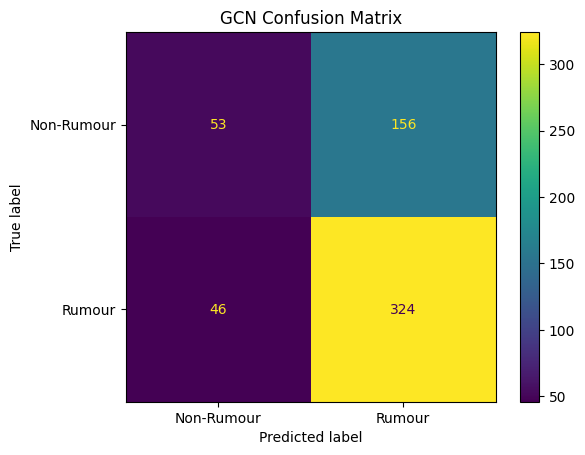

In [ ]:
from sklearn.metrics import (
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Rumour",
        "Rumour"
    ]
)

disp.plot()

plt.title(
    "GCN Confusion Matrix"
)

plt.savefig(
    "gcn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

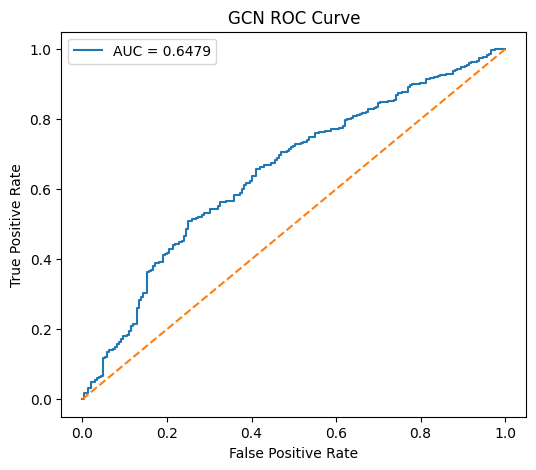

In [ ]:
from sklearn.metrics import (
    roc_curve,
    auc
)

fpr, tpr, _ = roc_curve(
    y_true,
    y_prob
)

roc_auc_plot = auc(
    fpr,
    tpr
)

import matplotlib.pyplot as plt

plt.figure(
    figsize=(6,5)
)

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc_plot:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "GCN ROC Curve"
)

plt.legend()

plt.savefig(
    "gcn_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import files

files.download(
    "gcn_metrics.txt"
)

files.download(
    "gcn_predictions.csv"
)

files.download(
    "gcn_confusion_matrix.png"
)

files.download(
    "gcn_roc_curve.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>